# Evaluate Omni-FinAI with NVIDIA NeMo AutoModel

Extraction checks every requested numeric field; QA checks the computed growth percentage. Summary scoring measures required numeric coverage only, not overall quality, faithfulness, or financial reasoning. Dataset and configuration hashes accompany each run.

In [ ]:
import os, pathlib, subprocess, sys
REPO_URL = "https://github.com/virginiakm1988/omni-finai-nvidia.git"
GIT_REF = "v0.1.0"  # Published, fixed source release for this tutorial.
checkout = pathlib.Path("/content/omni-finai-nvidia")
if not checkout.exists():
    subprocess.run(["git", "clone", REPO_URL, str(checkout)], check=True)
subprocess.run(["git", "-C", str(checkout), "checkout", GIT_REF], check=True)
os.chdir(checkout)
subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-e", ".[notebook]"], check=True)
print("Source revision:", subprocess.check_output(["git", "rev-parse", "HEAD"], text=True).strip())


## Architecture

The diagram is authored for this tutorial. Each arrow maps to executable package code. Fixture and live results remain explicitly separated.

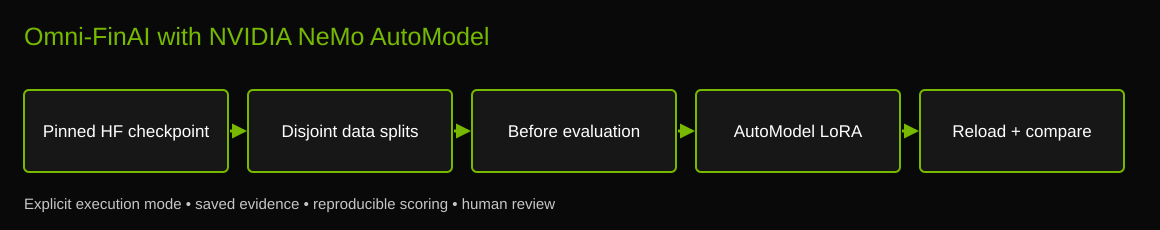

In [2]:
from IPython.display import SVG, display
display(SVG(filename="assets/overview.svg"))

In [3]:
subprocess.run([sys.executable, "-m", "project_demo", "demo", "--mode", "fixture", "--output-dir", "runs/evaluation-tutorial"], check=True)
import json
latest = json.loads(pathlib.Path("runs/evaluation-tutorial/latest.json").read_text())
saved = str(pathlib.Path(latest["run"]) / "result.json")
subprocess.run([sys.executable, "-m", "project_demo", "evaluate", "--results", saved, "--output-dir", "runs/rescore"], check=True)


CompletedProcess(args=['[workspace]\\work\\agent-finance-venv\\Scripts\\python.exe', '-m', 'project_demo', 'evaluate', '--results', '[workspace]\\outputs\\nvidia-repos\\omni-finai-nvidia\\runs\\evaluation-tutorial\\20261116T093235-79278f93\\result.json', '--output-dir', 'runs/rescore'], returncode=0)

## Evaluate your live output

Replace `saved` with a recorded live result. Keep the same scoring rules. For agent projects, the playbook also shows remote Helix scoring. No model is called during rescoring. Record remaining human-review questions separately from automatic metrics.

In [4]:
import ipywidgets as widgets
from IPython.display import display
saved_path = widgets.Text(value=saved, description="Result path", layout=widgets.Layout(width="95%"))
display(saved_path)


Text(value='[workspace]\\outputs\\nvidia-repos\\omni-finai-nvidia\…

In [5]:
subprocess.run([sys.executable, "-m", "project_demo", "evaluate", "--results", saved_path.value, "--output-dir", "runs/selected-rescore"], check=True)
display(json.loads(pathlib.Path(saved_path.value).read_text(encoding="utf-8")))


{'command': 'demo',
 'mode': 'fixture',
 'status': 'succeeded',
 'config': {'project': 'omni-finai',
  'profile': 'small',
  'seed': 42,
  'max_requests': 10,
  'model': 'nvidia/nemotron-3.5-lightning-30b-a3b',
  'base_url': 'https://integrate.api.nvidia.com/v1',
  'profiles': {'original': {'model_id': 'ichanchiu/Llama-3.1-Omni-FinAI-70B',
    'revision': '8f9e1ccba75181c7ca95df77e8313a76bfdd4a50',
    'gated': False,
    'min_free_disk_gib': 150},
   'small': {'model_id': 'Qwen/Qwen2.5-0.5B-Instruct',
    'revision': '7ae557604adf67be50417f59c2c2f167def9a775',
    'gated': False,
    'min_free_disk_gib': 3}},
  'max_new_tokens': 160,
  'train_steps': 12,
  'train_size': 48,
  'validation_size': 12,
  'test_size': 12},
 'config_sha256': '01e7b01df23b167154c18916827239a636073844022f24e2e51b3f833d88497c',
 'started_at': '2026-11-16T09:32:35.660542+00:00',
 'python': '3.12.14',
 'result': {'predictions': [{'id': 'test-000',
    'task': 'extract',
    'prediction': '{"revenue_million": 930